<a href="https://colab.research.google.com/github/jumafernandez/modelado-gestion-datos-untref/blob/main/codigo/r_api_series_tiempo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Series de tiempo de Argentina desde R

**Modelado y Gestión de Datos - UNTREF - 2026**

En este notebook consultamos desde R la API de Series de Tiempo de Argentina, que publica miles de series de organismos como el INDEC y el BCRA y no requiere credenciales. Es la misma API del script de ejemplo [S07] en Python, con cosas que no se ven ahí: buscar una serie, armar el pedido paso a paso, controlar cuántos datos devuelve, recibir CSV en lugar de JSON, pedirle a la API que haga cálculos y entender sus mensajes de error.

Cada celda se ejecuta con **Shift + Enter** o con el botón ▶ de su izquierda. Algunos pedidos pueden tardar unos segundos, o más cuando la API está cargada: hay que esperar a que la celda termine.

## 1. El paquete httr2

httr2 arma y envía pedidos HTTP desde R. Colab ya lo trae instalado, igual que ggplot2.

In [1]:
library(httr2)
library(ggplot2)
options(repr.plot.width = 10, repr.plot.height = 4)   # gráficos más anchos en Colab

## 2. Buscar una serie

Cada serie tiene un identificador. Para encontrarlo, la API tiene un endpoint de búsqueda, `search`. El pedido se arma por partes: `request()` recibe la dirección base, `req_url_path_append()` agrega el endpoint y `req_url_query()`, los parámetros. `req_perform()` lo envía y `resp_body_json()` convierte la respuesta JSON en datos de R.

In [2]:
API <- "https://apis.datos.gob.ar/series/api"
query <- "tipo de cambio"


busqueda <- request(API) |>
  req_url_path_append("search") |>
  req_url_query(q = query, limit = 10) |>
  req_perform()

resultado <- resp_body_json(busqueda, simplifyVector = TRUE)
resultado$data$field[, c("id", "description", "frequency", "time_index_end")]

,id,description,frequency,time_index_end
,<chr>,<chr>,<chr>,<chr>
1,92.2_TIPO_CAMBIION_0_0_21_24,Tipo de cambio de valuación (peso por dólar),R/P1D,2026-08-31
2,175.1_DR_FINAPRA_0_0_23,Dólar Financiero. Compra,R/P1D,1983-01-02
3,175.1_DR_ESTANSE_0_0_20,Dólar Estadounidense,R/P1D,2026-08-31
4,92.1_TCV_0_0_21,Tipo de cambio de valuación (peso por dólar),R/P1M,2026-08-01
5,168.1_T_CAMBIMAE_D_0_0_15,Tipo de Cambio MAE,R/P1D,2026-08-31
6,175.1_DR_LIBRPRA_0_0_18,Dólar Libre. Compra,R/P1D,1992-01-01
7,bcra_sml_006,Tipo de cambio PTAX diario.,R/P1D,2021-08-02
8,168.1_T_CAMBI500_D_0_0_17,Tipo de Cambio A3500,R/P1D,2026-08-31
9,175.1_DR_FINANTA_0_0_21,Dólar Financiero Esp. Venta,R/P1D,1976-03-04


La frecuencia sigue la norma ISO 8601: `R/P1D` es diaria, `R/P1M` mensual y `R/P1Y` anual.

## 3. Pedir una serie

Pedimos el índice de precios al consumidor (IPC) nacional del INDEC desde 2017. Antes de enviarlo, el pedido se puede mirar: muestra el método y la URL que se va a consultar.

In [3]:
pedido <- request(API) |>
  req_url_path_append("series") |>
  req_url_query(ids = "148.3_INIVELNAL_DICI_M_26", start_date = "2017-01-01")

pedido

<httr2_request>
GET https://apis.datos.gob.ar/series/api/series?ids=148.3_INIVELNAL_DICI_M_26&start_date=2017-01-01
Body: empty

In [4]:
respuesta <- req_perform(pedido)

resp_status(respuesta)          # 200: el pedido salió bien
resp_content_type(respuesta)    # el formato de la respuesta

[1] 200

[1] "application/json"

La respuesta trae los datos en `data`, como pares de fecha y valor, y en `count` cuántos valores tiene la serie en el período pedido.

In [5]:
cuerpo <- resp_body_json(respuesta, simplifyVector = TRUE)

names(cuerpo)
cuerpo$count          # cuántos valores tiene la serie desde 2017
nrow(cuerpo$data)     # cuántos vinieron en esta respuesta

[1] "data"   "count"  "meta"   "params"

[1] 116

[1] 100

Vinieron menos valores de los que hay: si no se le indica otra cosa, la API entrega 100 por pedido. Con `limit` se piden hasta 1.000; para series más largas se pide de a partes con `start`, que indica desde qué posición empezar. Es la paginación, que usan casi todas las APIs.

In [6]:
respuesta <- pedido |>
  req_url_query(limit = 1000) |>
  req_perform()

cuerpo <- resp_body_json(respuesta, simplifyVector = TRUE)
nrow(cuerpo$data)

[1] 116

Los pares llegan como texto: los pasamos a un data frame con fechas y números.

In [7]:
ipc <- data.frame(fecha = as.Date(cuerpo$data[, 1]),
                  ipc = as.numeric(cuerpo$data[, 2]))
tail(ipc)

,fecha,ipc
,<date>,<dbl>
111,2026-03-01,11077.06
112,2026-04-01,11363.09
113,2026-05-01,11607.39
114,2026-06-01,11826.41
115,2026-07-01,12076.39
116,2026-08-01,12276.77


En `meta` vienen los metadatos: qué es la serie, en qué unidad está y quién la publica, lo que hay que documentar cuando se usan datos de una API. La primera fila describe el índice de tiempo; la segunda, la serie.

In [8]:
cuerpo$meta$field$description[2]
cuerpo$meta$field$units[2]
cuerpo$meta$dataset$source[2]

[1] "IPC. Nivel General Nacional. Base dic 2016. Mensual."

[1] "Índice"

[1] "Instituto Nacional de Estadística y Censos (INDEC)"

## 4. Pedir CSV y que la API haga la cuenta

Con `format = "csv"` la API responde en CSV, que R lee directamente como data frame. Además, una misma consulta puede traer varias series, con los identificadores separados por comas, y transformarlas: con `representation_mode = "percent_change_a_year_ago"`, la API calcula la variación interanual. Comparamos la inflación del nivel general con la núcleo, que excluye los precios regulados y los estacionales. La variación llega como proporción: 0,33 es 33%.

In [9]:
respuesta <- request(API) |>
  req_url_path_append("series") |>
  req_url_query(ids = "148.3_INIVELNAL_DICI_M_26,148.3_INUCLEONAL_DICI_M_19",
                representation_mode = "percent_change_a_year_ago",
                format = "csv", limit = 1000) |>
  req_perform()

inflacion <- read.csv(text = resp_body_string(respuesta))
names(inflacion) <- c("fecha", "general", "nucleo")
inflacion$fecha <- as.Date(inflacion$fecha)
tail(inflacion)

,fecha,general,nucleo
,<date>,<dbl>,<dbl>
100,2026-03-01,0.3260675,0.3358683
101,2026-04-01,0.3235045,0.3238545
102,2026-05-01,0.3319652,0.3200488
103,2026-06-01,0.3354773,0.3181779
104,2026-07-01,0.3382569,0.3221141
105,2026-08-01,0.3354117,0.3190889


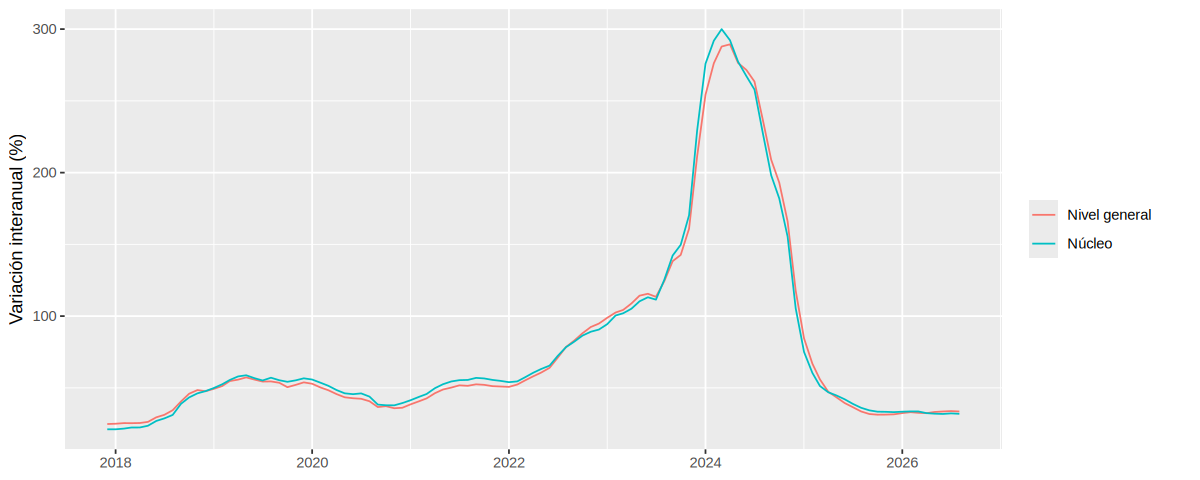

In [10]:
ggplot(inflacion, aes(x = fecha)) +
  geom_line(aes(y = general * 100, color = "Nivel general")) +
  geom_line(aes(y = nucleo * 100, color = "Núcleo")) +
  labs(x = NULL, y = "Variación interanual (%)", color = NULL)

## 5. Integrar series de distintas fuentes

La API también alinea series de distinta frecuencia. El tipo de cambio del BCRA es diario y tiene miles de valores; con `collapse = "month"` y `collapse_aggregation = "avg"`, la API lo resume en promedios mensuales y lo devuelve junto al IPC del INDEC, mes a mes.

Con las dos series alineadas calculamos el dólar a precios del último mes: el tipo de cambio de cada mes, ajustado por la inflación acumulada desde entonces. `na.omit()` descarta los meses que todavía no tienen las dos series.

In [11]:
respuesta <- request(API) |>
  req_url_path_append("series") |>
  req_url_query(ids = "148.3_INIVELNAL_DICI_M_26,92.2_TIPO_CAMBIION_0_0_21_24",
                collapse = "month", collapse_aggregation = "avg",
                start_date = "2017-01-01", format = "csv", limit = 1000) |>
  req_perform()

precios <- read.csv(text = resp_body_string(respuesta))
names(precios) <- c("fecha", "ipc", "dolar")
precios$fecha <- as.Date(precios$fecha)
precios <- na.omit(precios)

ultimo_ipc <- precios$ipc[nrow(precios)]
precios$dolar_real <- precios$dolar * ultimo_ipc / precios$ipc
tail(precios)

,fecha,ipc,dolar,dolar_real
,<date>,<dbl>,<dbl>,<dbl>
111,2026-03-01,11077.06,1395.978,1547.169
112,2026-04-01,11363.09,1381.407,1492.482
113,2026-05-01,11607.39,1395.833,1476.328
114,2026-06-01,11826.41,1450.098,1505.318
115,2026-07-01,12076.39,1487.640,1512.323
116,2026-08-01,12276.77,1498.713,1498.713


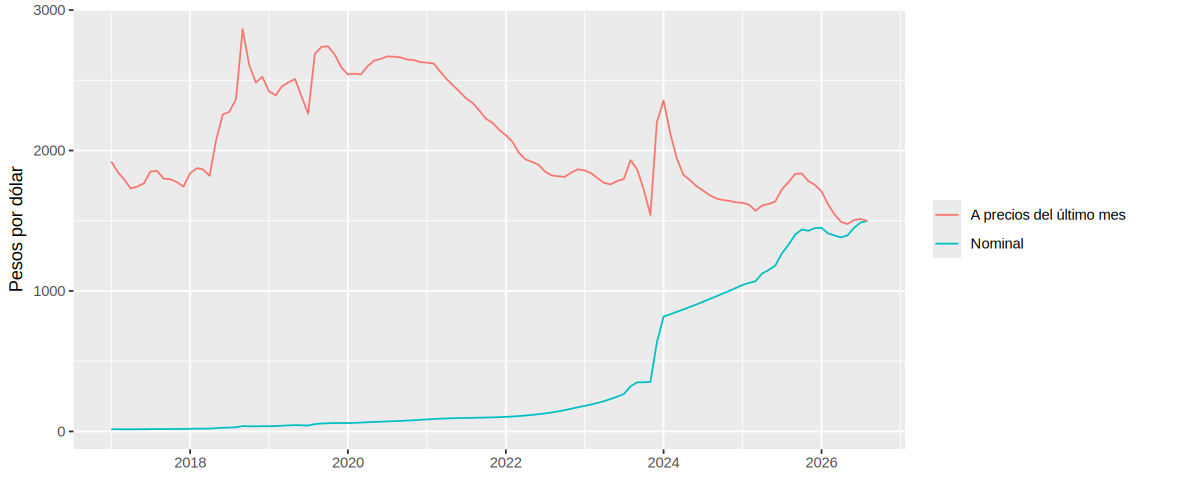

In [12]:
ggplot(precios, aes(x = fecha)) +
  geom_line(aes(y = dolar, color = "Nominal")) +
  geom_line(aes(y = dolar_real, color = "A precios del último mes")) +
  labs(x = NULL, y = "Pesos por dólar", color = NULL)

## 6. Cuando algo sale mal

Si el pedido tiene un error, la API responde con un código de estado de la familia 400 y, en el cuerpo, un mensaje que explica qué pasó. httr2 convierte esos códigos en un error de R; con `try()` la celda muestra el error sin detenerse, y `last_response()` devuelve la última respuesta para leer el mensaje.

In [13]:
pedido_con_error <- request(API) |>
  req_url_path_append("series") |>
  req_url_query(ids = "148.3_SERIE_QUE_NO_EXISTE")

try(req_perform(pedido_con_error))
resp_status(last_response())
resp_body_json(last_response())

Error in req_perform(pedido_con_error) : HTTP 400 Bad Request.


[1] 400

$errors
$errors[[1]]
$errors[[1]]$error
[1] "Serie inexistente: 148.3_SERIE_QUE_NO_EXISTE"



$failed_series
$failed_series[[1]]
[1] "148.3_SERIE_QUE_NO_EXISTE"

Los códigos de la familia 400 indican un problema en el pedido, como un identificador que no existe, un parámetro mal escrito o una clave inválida. Los de la familia 500 indican un problema del servidor, que suele resolverse volviendo a intentar más tarde.

---

## Desde tu computadora

El mismo código funciona en RStudio: los paquetes se instalan una sola vez con `install.packages(c("httr2", "ggplot2"))`. La [documentación de la API](https://datosgobar.github.io/series-tiempo-ar-api/) describe todos los parámetros.

Para el trabajo práctico de la unidad, cualquiera de estos data frames se puede guardar en PostgreSQL con `dbWriteTable()`, como en el script de ejemplo [S05].